# Alunos
- Matheus Peixoto Ribeiro Vieira - 22.1.4104
- Pedro Henrique Rabelo Leão de Oliveira - 22.1.4022

In [95]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import homogeneity_score, completeness_score, v_measure_score, silhouette_score, accuracy_score, confusion_matrix
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [93]:
df = pd.read_csv("data/train.csv")
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


# Preparando os dados para o modelo

**Classificando os atributos**:

PassengerId - Discreto (já que ele assume valores inteiros e contáveis)

Pclass - Categórico Ordinal (já que representa uma categoria com ordem natural)

Name - Categórico Nominal (já que representa uma categoria sem ordem)

Sex - Binário Assimétrico (já que é um atributo de apenas dois valores e ambos não tem a mesma importância, logo, se houvesse uma troca entre os valores alteraria a análise)

Age - Contínuo (já que ele pode assumir qualquer valor dentro de um intervalo)

SibSp - Discreto (já que ele assume valores inteiros e contáveis)

Parch - Discreto (já que ele assume valores inteiros e contáveis)

Ticket - Categórico Nominal (já que representa uma categoria sem ordem)

Fare - Contínuo (já que ele pode assumir qualquer valor dentro de um intervalo)

Cabin - Categórico Nominal (já que representa uma categoria sem ordem)

Embarked - Categórico Nominal (já que representa uma categoria sem ordem)

Aplicando as mesmas transformações que na atividade anterior

In [3]:
atributosNumericos = ['Age', 'SibSp', 'Parch', 'Fare']
# Suavizando ruídos
for atributo in atributosNumericos:
    Q1 = df[atributo].quantile(0.25)
    Q3 = df[atributo].quantile(0.75)
    AIQ = Q3 - Q1
    upper_bound = Q3 + 1.5 * AIQ
    bounds, _ = pd.cut(df[atributo], 4, retbins=True)
    for index, row in df.iterrows():
        if row[atributo] > upper_bound:
            mean = (bounds[index].left + bounds[index].right) / 2.0
            df.loc[index, atributo] = mean


df = df.drop(['PassengerId', 'Name', 'Ticket'], axis=1)

# Preenchendo valores ausentes
mean_age = df['Age'].mean()
df['Age'] = df['Age'].fillna(mean_age)

# U = Unknown
df['Cabin'] = df['Cabin'].fillna('U')
# O número da cabine é formado por uma letra seguida de um número, portanto, se eu pegar
# essa letra inicial, pode me trazer uma informação interessante da localização do passageiro no navio
df['Cabin'] = df['Cabin'].astype(str).str[0]

mode = df['Embarked'].mode()[0]
df['Embarked'] = df['Embarked'].fillna(mode)

df["Sex"] = df["Sex"].map({"male": 0, "female": 1})

# Aplicando one-hot encoded em atributos categóricos nominais e sex
# cols_to_encode = ['Embarked', 'Cabin']
# df = pd.get_dummies(df, columns=cols_to_encode, prefix=cols_to_encode, dtype=int)
df["Embarked"] = df["Embarked"].astype("category").cat.codes
df["Cabin"] = df["Cabin"].astype("category").cat.codes

df['Pclass'] = df['Pclass'].astype(int)

# Normalizando atributos numéricos
for atributo in atributosNumericos+['Pclass']:
    min = df[atributo].min()
    max = df[atributo].max()
    df[atributo] = (df[atributo] - min) / (max - min)

df

/tmp/ipykernel_76136/3490112506.py:12: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.747' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df.loc[index, atributo] = mean


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,0,1.0,0,0.309913,0.142857,0.000000,0.016173,8,2
1,1,0.0,1,0.539691,0.142857,0.000000,0.142286,2,0
2,1,1.0,1,0.367357,0.000000,0.000000,0.017678,8,2
3,1,0.0,1,0.496607,0.142857,0.000000,0.118451,2,2
4,0,1.0,0,0.496607,0.000000,0.000000,0.017957,8,2
...,...,...,...,...,...,...,...,...,...
886,0,0.5,0,0.381718,0.000000,0.000000,0.028999,8,2
887,1,0.0,1,0.266829,0.000000,0.000000,0.066921,1,2
888,0,1.0,1,0.420543,0.142857,0.428571,0.052310,8,2
889,1,0.0,0,0.367357,0.000000,0.000000,0.066921,2,0


In [4]:
labels = df.iloc[:, 0]
features = df.iloc[:, 1:]

# Matriz de dissimialridade

In [ ]:
class DissimilarityMatrix:
    def __init__(self, dataframe):
        self.dataframe = dataframe.copy()
        self.cols = dataframe.columns
        m = dataframe.shape[0]
        self.m = m
        self.dm = np.zeros((m, m), dtype=np.float32)

        self.types = {
            'Pclass': "ordinal",
            'Age': "discreto",
            'SibSp': "discreto",
            'Parch': "discreto",
            'Fare': "continuo",
            'Sex': "binary_symmetric",
            'Cabin': "categorical",
            'Embarked': "categorical",
        }

        self.X = self.dataframe[self.cols].to_numpy(dtype=np.float32, copy=False)

        lista_de_tipos = [self.types[c] for c in self.cols]
        self.mascara_numericos = np.array([t in ("continuo","ordinal","discreto") for t in lista_de_tipos])
        self.mascara_categoricos_simetricos = np.array([(t == "categorical") or (t=="binary_symmetric") for t in lista_de_tipos])
        self.mascara_assimetricos = np.array([t == "binary_assymmetric" for t in lista_de_tipos])


    def calculate_delta(self, tipo, xi, xj):
        if tipo == "binary_assymmetric" and xi == 0 and xj == 0:
            return 0
        return 1

    def calculate_d(self, tipo, xi, xj):
        if (tipo == "categorical") or ("binary" in tipo):
            return int(xi != xj)
        if tipo in ("continuo","ordinal","discreto"):
            return abs(xi - xj)
        return 0


    def calculate_dissimilarity(self):
        m = self.m

        D = np.zeros((m, m), dtype=np.float32)
        denom = np.zeros((m, m), dtype=np.float32)

        if self.mascara_numericos.any():
            Xn = self.X[:, self.mascara_numericos]
            D += np.abs(Xn[:, None, :] - Xn[None, :, :]).sum(axis=2)
            denom += self.mascara_numericos.sum()

        if self.mascara_categoricos_simetricos.any():
            Xc = self.X[:, self.mascara_categoricos_simetricos]
            D += (Xc[:, None, :] != Xc[None, :, :]).astype(np.float32).sum(axis=2)
            denom += self.mascara_categoricos_simetricos.sum()


        self.dm = D / denom
        return self.dm

dm = DissimilarityMatrix(features)
matriz = dm.calculate_dissimilarity()
matriz

array([[0.        , 0.54448634, 0.15022591, ..., 0.19691733, 0.40638128,
        0.16094795],
       [0.54448634, 0.        , 0.42997473, ..., 0.45471188, 0.17381936,
        0.5442527 ],
       [0.15022591, 0.42997473, 0.        , ..., 0.08240571, 0.5061554 ,
        0.2608196 ],
       ...,
       [0.19691733, 0.45471188, 0.08240571, ..., 0.        , 0.5799031 ,
        0.329929  ],
       [0.40638128, 0.17381936, 0.5061554 , ..., 0.5799031 , 0.        ,
        0.391975  ],
       [0.16094795, 0.5442527 , 0.2608196 , ..., 0.329929  , 0.391975  ,
        0.        ]], dtype=float32)

# A) Realizando agrupamentos

In [ ]:
kmeans = KMeans(n_clusters=2)
km_labels = kmeans.fit_predict(matriz)
km_labels

array([0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0,

In [57]:
agg = AgglomerativeClustering(n_clusters=2)
agg_labels = agg.fit_predict(matriz)
agg_labels

/home/matheus/.local/lib/python3.10/site-packages/scipy/cluster/hierarchy.py:796: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  return linkage(y, method='ward', metric='euclidean')


array([0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0,

# B) Avaliando

In [97]:
def avaliar(y_true, y_pred, X):
    h = homogeneity_score(y_true, y_pred)
    c = completeness_score(y_true, y_pred)
    v = v_measure_score(y_true, y_pred)
    sil = silhouette_score(X, y_pred)

    cm = confusion_matrix(y_true, y_pred)

    return h, c, v, sil, cm

km_h, km_c, km_v, km_s, km_cm = avaliar(labels, km_labels, X=matriz)
ag_h, ag_c, ag_v, ag_s, ag_cm = avaliar(labels, agg_labels, X=matriz)

print("homogeneity_score")
print(f"K médias : {km_h}")
print(f"Aggregate: {ag_h}")
print("="*50)
print("completeness_score")
print(f"K médias : {km_c}")
print(f"Aggregate: {ag_c}")
print("="*50)
print("v_measure_score")
print(f"K médias : {km_v}")
print(f"Aggregate: {ag_v}")
print("="*50)
print("silhouette_score")
print(f"K médias : {km_s}")
print(f"Aggregate: {ag_s}")
print("="*50)
print(km_cm)
print(ag_cm)


homogeneity_score
K médias : 0.09222521681618351
Aggregate: 0.09051070187319245
completeness_score
K médias : 0.10581870758370887
Aggregate: 0.11146580220813036
v_measure_score
K médias : 0.09855544197771084
Aggregate: 0.09990120423763944
silhouette_score
K médias : 0.46900519728660583
Aggregate: 0.47079017758369446
[[470  79]
 [183 159]]
[[486  63]
 [199 143]]


Em geral, ambos os modelos apresentaram resultados bem similares, todavia, não conseguiram obter uma separação tão boa dos dados e suas classes. Dessa forma, mostra-se como o uso dos modelos com classificadores faz mais sentido para esse problema.

Os valores da métrica de homogeneidade mostram que os dados possuem muitas impurezas, uma vez que os seus valores estão muito baixos e próximos de zero.

Em relação à completude, é notório que as amostras de uma das classes estão presentes nas outras. Tal resultado pode ser ainda complementado com a visualização da matrix de confusão para ambos os modelos.

Já o v-measure, é a média harmônica da homogeneidade e da completude, assim, como ambos os valores estão baixos, faz sentido que seu resultado também seja baixo.

A silhueta, por outro lado, já mostra resultados mais otimistas para os modelos, uma vez que o seu resultado positivo e próximo de 0.5 indica uma separação mais moderada dos clusters, mas ainda assim não estão garantindo um verdadeiro alinhamento com as classes verdadeiras.



# C) Analisando os clusters

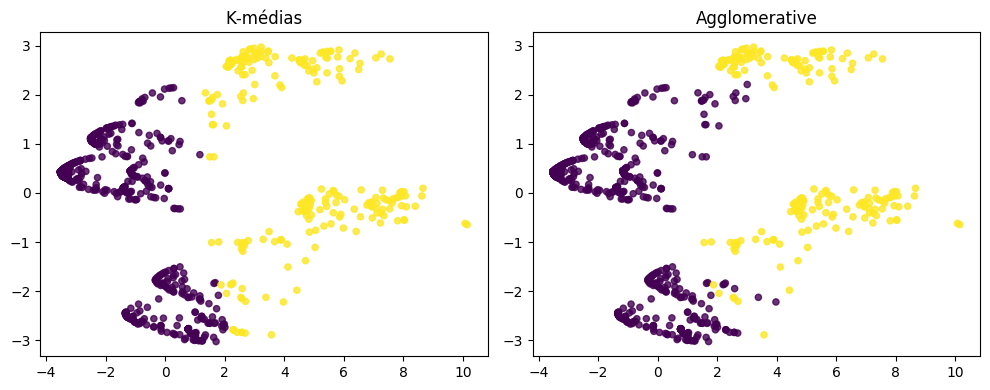

In [98]:
pca = PCA(n_components=2, random_state=1024)
matriz2D = pca.fit_transform(matriz)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# K-means
sc0 = ax[0].scatter(matriz2D[:, 0], matriz2D[:, 1], c=km_labels, s=20, alpha=0.8)
ax[0].set_title("K‑médias")


# Agglomerative
sc1 = ax[1].scatter(matriz2D[:, 0], matriz2D[:, 1], c=agg_labels, s=20, alpha=0.8)
ax[1].set_title("Agglomerative")

plt.tight_layout()
plt.show()


Os pontos que estão dentro dos grupos estão próximos entre si e um pouco distantes do outro, mas nem tanto, o que justica a silhueta de 0.47.

As fronteiras estão bem similares, assim como a distribuição dos itens. Dessa forma, fica mais evidente entender o porque das metricas terem dado resultados tão similares.

